<a href="https://www.kaggle.com/code/aamir28/nlp-assignment-2-pseudocode?scriptVersionId=364519919" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# NLP Assignment 2: Pseudocode + Python on the Bollywood Movies Dataset

**Problems covered**

1. Text preprocessing (apply every technique you think is necessary)
2. Number of words in the corpus and vocabulary size, using just Python
3. One Hot Encoding
4. Bag of Words: vocabulary and word counts
5. Bag of Bi-grams and Bag of Tri-grams: observation on dimensionality
6. TF-IDF: IDF scores and vocabulary

Each problem has: **what and why**, **pseudocode**, **Python code**, and a short **observation** space for your assignment.

> Dataset: `bollywood_movies_nlp_dataset.csv` with columns `movie`, `description`, `genre`.
> Each movie description is treated as one **document**, and all 168 descriptions together form the **corpus**.

In [1]:
# Run once (Kaggle/Colab usually already have most of these)
!pip install -q nltk emoji beautifulsoup4 scikit-learn matplotlib

In [2]:
import re, string, os
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk

for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)

pd.set_option("display.max_colwidth", 120)

## 0. Load the data

**Pseudocode**
```
FILE = "bollywood_movies_nlp_dataset.csv"
SEARCH for FILE in: current folder, the Kaggle input folder
df = READ csv from the first location where FILE exists
PRINT shape and first rows
```

In [3]:
candidates = [
    "bollywood_movies_nlp_dataset.csv",
    "/kaggle/input/datasets/aamir28/nlp-text-preprocessing-dataset/bollywood_movies_nlp_dataset.csv",
    "/kaggle/input/bollywood-movies-dataset-for-nlp/bollywood_movies_nlp_dataset.csv",
]
path = next((p for p in candidates if os.path.exists(p)), None)
if path is None and os.path.exists("/kaggle/input"):
    # Kaggle: search every attached input for the file
    for root, _, files in os.walk("/kaggle/input"):
        if "bollywood_movies_nlp_dataset.csv" in files:
            path = os.path.join(root, "bollywood_movies_nlp_dataset.csv")
            break
assert path, "Upload bollywood_movies_nlp_dataset.csv next to this notebook"

df = pd.read_csv(path)
print(path)
print(df.shape)
df.head()

/kaggle/input/datasets/aamir28/nlp-text-preprocessing-dataset/bollywood_movies_nlp_dataset.csv
(168, 3)


,movie,description,genre
0,Sholay,Two petty criminals are hired by a retired police officer to capture a ruthless dacoit terrorising a village. Friend...,"Action, Adventure"
1,Mughal-E-Azam,"Prince Salim falls in love with the court dancer Anarkali, defying his father Emperor Akbar. The epic tells a grand ...","Drama, Romance, History"
2,Mother India,A poor village woman struggles to raise her sons and uphold her principles amid hardship and debt. Her sacrifices ma...,Drama
3,Pyaasa,A disillusioned poet finds that the world values him more after his supposed death than during his life. A bitter lo...,"Drama, Musical"
4,Guide,"A tour guide helps an unhappy dancer become a star, but love and ego lead him down an unexpected spiritual path.","Drama, Romance"


## Problem 1. Preprocessing

**Why:** Raw text has inconsistent casing, leftover HTML, URLs, punctuation, emojis, slang, and many words that carry little meaning.
Every later problem (counting words, one hot encoding, bag of words, n-grams, TF-IDF) is only as good as the text we feed it.

**Which techniques we apply, and why (and which we skip)**

| Step | Apply? | Reason |
|---|---|---|
| Lowercasing | Yes | "Love" and "love" should be one word |
| Remove HTML tags | Yes | Harmless safety step, nothing in the content is lost |
| Remove URLs | Yes | Links add one-off useless tokens |
| Remove emojis | Yes | Models for bag-of-words cannot use them |
| Remove punctuation | Yes | Stops `village.` and `village` being two words |
| Chat word expansion | Yes | Cheap safety step (the descriptions are clean, so it rarely fires) |
| Tokenization | Yes | We need individual words |
| Stop word removal | Yes | Removes words like *the, is, of* that carry no topic information. We **keep negations** (*not, no, nor*) |
| Lemmatization | Yes | Real dictionary words, e.g. *villains* to *villain*, *falls* to *fall* |
| Stemming | No | Crude roots like *famili*. We use lemmatization instead |
| Spelling correction | No | Slow, and it damages proper nouns (names of actors, movies, places) |

**Pseudocode**
```
FUNCTION preprocess(text):
    text = remove_html(text)
    text = remove_urls(text)
    text = lowercase(text)
    text = remove_emoji(text)
    text = remove "'s" endings, and turn hyphens/slashes into spaces
    text = remove_punctuation(text)
    text = expand_chat_words(text)
    tokens = split text into words
    tokens = [t FOR t IN tokens IF t NOT IN stop_words]
    tokens = lemmatize each token using its part of speech
    RETURN tokens

FOR each description in the dataset:
    clean_tokens = preprocess(description)
    clean_text   = join clean_tokens with spaces
```

In [4]:
from bs4 import BeautifulSoup
import emoji
from nltk.corpus import stopwords, wordnet
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from nltk import pos_tag

# ---- individual steps ----
def remove_html(text):
    return BeautifulSoup(text, "html.parser").get_text()

def remove_urls(text):
    return re.sub(r"(https?://|www\.)\S+", "", text)

def lowercase(text):
    return text.lower()

def remove_emoji(text):
    return emoji.replace_emoji(text, replace="")

def remove_punctuation(text):
    text = re.sub(r"'s\b", "", text)          # srk's -> srk
    text = re.sub(r"[-/\u2013\u2014]", " ", text)  # curry-western -> curry western
    return text.translate(str.maketrans("", "", string.punctuation))

chat_words = {
    "omg": "oh my god", "imo": "in my opinion", "asap": "as soon as possible", "gr8": "great",
    "luv": "love", "thx": "thanks", "pls": "please", "plz": "please", "btw": "by the way",
    "idk": "i do not know", "lol": "laughing out loud", "fyi": "for your information",
    "u": "you", "ur": "your", "b4": "before", "2day": "today", "tbh": "to be honest",
    "bcoz": "because", "cuz": "because", "tmrw": "tomorrow",
}
def expand_chat_words(text):
    return " ".join(chat_words.get(w, w) for w in text.split())

# keep negations; they change meaning
stop_words = set(stopwords.words("english")) - {"not", "no", "nor"}

lem = WordNetLemmatizer()
def get_wordnet_pos(tag):
    return {"J": wordnet.ADJ, "V": wordnet.VERB, "N": wordnet.NOUN, "R": wordnet.ADV}.get(tag[0], wordnet.NOUN)

def lemmatize_tokens(tokens):
    return [lem.lemmatize(w, get_wordnet_pos(t)) for w, t in pos_tag(tokens)]

# ---- full pipeline ----
def preprocess(text):
    text = remove_html(text)
    text = remove_urls(text)
    text = lowercase(text)
    text = remove_emoji(text)
    text = remove_punctuation(text)
    text = expand_chat_words(text)
    tokens = [t for t in word_tokenize(text) if t not in stop_words]
    return lemmatize_tokens(tokens)

# quick test
print(df["description"].iloc[0])
print(preprocess(df["description"].iloc[0]))

Two petty criminals are hired by a retired police officer to capture a ruthless dacoit terrorising a village. Friendship, revenge and iconic dialogue define this curry-western classic.
['two', 'petty', 'criminal', 'hire', 'retired', 'police', 'officer', 'capture', 'ruthless', 'dacoit', 'terrorise', 'village', 'friendship', 'revenge', 'iconic', 'dialogue', 'define', 'curry', 'western', 'classic']


In [5]:
df["clean_tokens"] = df["description"].apply(preprocess)
df["clean_text"]   = df["clean_tokens"].str.join(" ")
df[["movie", "description", "clean_text"]].head(5)

,movie,description,clean_text
0,Sholay,Two petty criminals are hired by a retired police officer to capture a ruthless dacoit terrorising a village. Friend...,two petty criminal hire retired police officer capture ruthless dacoit terrorise village friendship revenge iconic d...
1,Mughal-E-Azam,"Prince Salim falls in love with the court dancer Anarkali, defying his father Emperor Akbar. The epic tells a grand ...",prince salim fall love court dancer anarkali defy father emperor akbar epic tell grand story love royal duty
2,Mother India,A poor village woman struggles to raise her sons and uphold her principles amid hardship and debt. Her sacrifices ma...,poor village woman struggle raise son uphold principle amid hardship debt sacrifice make symbol resilience
3,Pyaasa,A disillusioned poet finds that the world values him more after his supposed death than during his life. A bitter lo...,disillusion poet find world value suppose death life bitter look greed hypocrisy
4,Guide,"A tour guide helps an unhappy dancer become a star, but love and ego lead him down an unexpected spiritual path.",tour guide help unhappy dancer become star love ego lead unexpected spiritual path


In [6]:
raw_vocab   = df["description"].str.lower().str.split().explode().nunique()
clean_vocab = len({t for toks in df["clean_tokens"] for t in toks})
print("Vocabulary before preprocessing (lowercase + split):", raw_vocab)
print("Vocabulary after preprocessing                     :", clean_vocab)

Vocabulary before preprocessing (lowercase + split): 1210
Vocabulary after preprocessing                     : 946


**Observation (Problem 1)**

- Which preprocessing steps changed the text the most on this dataset, and which barely did anything (hint: the descriptions are already fairly clean)?
- How much did the vocabulary shrink?
- Why did we keep `not`, `no`, `nor` and skip spelling correction?

*Your answer:*

## Problem 2. Number of words and vocabulary, using just Python

**Why:** The **total number of words** (tokens) tells us the size of the corpus. The **vocabulary** is the set of **unique** words. The ratio between the two tells us how repetitive the text is.

We use only built-in Python here: `str.split()`, `for` loops, `set` and `dict`. No NLTK, no sklearn.

**Pseudocode**
```
total_words = 0
vocabulary  = EMPTY set
frequency   = EMPTY dictionary

FOR each document IN corpus:
    words = document split on spaces
    total_words = total_words + number of words
    FOR each word IN words:
        ADD word to vocabulary          # a set ignores duplicates
        frequency[word] = frequency[word] + 1

PRINT total_words
PRINT size of vocabulary
```

In [7]:
def corpus_stats(corpus):
    total_words = 0
    vocabulary = set()
    frequency = {}
    for document in corpus:
        words = document.split()
        total_words += len(words)
        for word in words:
            vocabulary.add(word)
            frequency[word] = frequency.get(word, 0) + 1
    return total_words, vocabulary, frequency

raw_corpus   = df["description"].tolist()
clean_corpus = df["clean_text"].tolist()

# Raw text, lowercased only, so "Love" and "love" are not counted as different words
raw_total, raw_vocab_set, _ = corpus_stats([d.lower() for d in raw_corpus])
# Preprocessed text
total_words, vocabulary, frequency = corpus_stats(clean_corpus)

print("RAW text (lowercased)")
print("  Total words      :", raw_total)
print("  Unique words     :", len(raw_vocab_set))
print()
print("PREPROCESSED text")
print("  Total words      :", total_words)
print("  Unique words     :", len(vocabulary))
print("  Total / unique   :", round(total_words / len(vocabulary), 2), "occurrences per word on average")

RAW text (lowercased)
  Total words      : 2925
  Unique words     : 1210

PREPROCESSED text
  Total words      : 1785
  Unique words     : 946
  Total / unique   : 1.89 occurrences per word on average


In [8]:
# Peek at the vocabulary and the most frequent words, still pure Python
print("First 20 vocabulary words:", sorted(vocabulary)[:20])
top10 = sorted(frequency.items(), key=lambda kv: kv[1], reverse=True)[:10]
print("Top 10 words:", top10)

First 20 vocabulary words: ['13th', '1857', '1990s', '1992', '1993', '93', 'abandon', 'abducts', 'abuse', 'abusive', 'accept', 'accident', 'accidental', 'accidentally', 'account', 'accuse', 'across', 'actor', 'actress', 'adaptation']
Top 10 words: [('love', 39), ('man', 35), ('woman', 29), ('fall', 21), ('family', 19), ('young', 18), ('life', 16), ('two', 15), ('father', 13), ('become', 13)]


**Observation (Problem 2)**

- How many words are in the corpus, and how many are unique?
- Preprocessing removed stop words, so the total drops a lot, but the vocabulary drops much less. Why?
- What does the average number of occurrences per word tell you about how repetitive this dataset is?

*Your answer:*

## Problem 3. One Hot Encoding

**Why:** Models need numbers. **One Hot Encoding (OHE)** turns each word into a vector as long as the vocabulary: all zeros except a single `1` at the word's own position.

Example with vocabulary `[fall, love, village]`: `love` becomes `[0, 1, 0]`.

A document is then a **matrix** with one row per word (shape: number of words by vocabulary size).

**Pseudocode**
```
vocabulary = sorted list of unique words in the corpus
word_to_index = { word: position FOR each word IN vocabulary }
V = size of vocabulary

FUNCTION one_hot(word):
    vector = list of V zeros
    vector[ word_to_index[word] ] = 1
    RETURN vector

FUNCTION encode_document(tokens):
    RETURN [ one_hot(w) FOR w IN tokens ]     # matrix: len(tokens) x V
```

In [9]:
# 1) Tiny demo so the idea is visible
toy_docs = [["love", "story"], ["village", "love", "family"], ["story", "family"]]
toy_vocab = sorted({w for d in toy_docs for w in d})
toy_idx = {w: i for i, w in enumerate(toy_vocab)}

def one_hot_toy(word):
    v = [0] * len(toy_vocab)
    v[toy_idx[word]] = 1
    return v

print("Toy vocabulary:", toy_vocab)
for w in toy_vocab:
    print(f"{w:8s}", one_hot_toy(w))
print()
print("Document ['village','love','family'] as a matrix:")
print(np.array([one_hot_toy(w) for w in toy_docs[1]]))

Toy vocabulary: ['family', 'love', 'story', 'village']
family   [1, 0, 0, 0]
love     [0, 1, 0, 0]
story    [0, 0, 1, 0]
village  [0, 0, 0, 1]

Document ['village','love','family'] as a matrix:
[[0 0 0 1]
 [0 1 0 0]
 [1 0 0 0]]


In [10]:
# 2) Now on the real corpus
vocabulary_list = sorted(vocabulary)           # `vocabulary` comes from Problem 2
word_to_index = {w: i for i, w in enumerate(vocabulary_list)}
V = len(vocabulary_list)

def one_hot(word):
    vec = np.zeros(V, dtype=int)
    vec[word_to_index[word]] = 1
    return vec

def encode_document(tokens):
    return np.array([one_hot(w) for w in tokens])

doc_tokens = df["clean_tokens"].iloc[0]
ohe_doc = encode_document(doc_tokens)

print("Movie           :", df["movie"].iloc[0])
print("Tokens          :", doc_tokens)
print("Vocabulary size :", V)
print("Matrix shape    :", ohe_doc.shape, "(words x vocabulary)")
print("Position of the 1 in each row:", ohe_doc.argmax(axis=1).tolist())
print("Rows sum to 1?  :", bool((ohe_doc.sum(axis=1) == 1).all()))
print()
print("one_hot('love') has", int(one_hot('love').sum()), "one and", V - 1, "zeros")

Movie           : Sholay
Tokens          : ['two', 'petty', 'criminal', 'hire', 'retired', 'police', 'officer', 'capture', 'ruthless', 'dacoit', 'terrorise', 'village', 'friendship', 'revenge', 'iconic', 'dialogue', 'define', 'curry', 'western', 'classic']
Vocabulary size : 946
Matrix shape    : (20, 946) (words x vocabulary)
Position of the 1 in each row: [889, 630, 201, 411, 712, 640, 600, 123, 742, 207, 848, 915, 354, 717, 431, 246, 228, 205, 926, 154]
Rows sum to 1?  : True

one_hot('love') has 1 one and 945 zeros


In [11]:
# Sparsity and memory: why plain OHE does not scale
n_tokens = total_words
dense_cells = n_tokens * V
print("Words in corpus          :", n_tokens)
print("Cells in full OHE matrix :", f"{dense_cells:,}")
print("Cells that are 1         :", f"{n_tokens:,}")
print(f"Percentage of zeros      : {100 * (1 - n_tokens / dense_cells):.3f}%")
print(f"Approx. size at 8 bytes per cell: {dense_cells * 8 / 1e6:.1f} MB")

Words in corpus          : 1785
Cells in full OHE matrix : 1,688,610
Cells that are 1         : 1,785
Percentage of zeros      : 99.894%
Approx. size at 8 bytes per cell: 13.5 MB


**Observation (Problem 3)**

- What is the shape of the OHE matrix for one document, and why?
- What percentage of the full corpus matrix is zeros? What problem does that cause (memory, speed)?
- OHE gives every word the same distance from every other word. What does that say about its ability to capture meaning (is *king* closer to *queen* than to *banana*)?
- OHE also ignores how many times a word occurs and has a different row count per document, so documents have different shapes. How does Bag of Words (Problem 4) fix this?

*Your answer:*

## Problem 4. Bag of Words

**Why:** Bag of Words (BoW) represents each **whole document** as one fixed-length vector. Position `j` holds **how many times** vocabulary word `j` occurs in that document. Word order is thrown away, like words dropped in a bag.

**Pseudocode**
```
vocabulary = sorted list of unique words in the corpus
FOR each document IN corpus:
    row = list of zeros, one per vocabulary word
    FOR each word IN document:
        row[ index of word ] = row[ index of word ] + 1
    ADD row to matrix                      # matrix shape: n_documents x V

word_total_count[word] = SUM of that word's column over all documents
```
Below: first **from scratch**, then with scikit-learn's `CountVectorizer`, and we check that both agree.

In [12]:
# From scratch
def bag_of_words(corpus_tokens, vocab_list):
    idx = {w: i for i, w in enumerate(vocab_list)}
    matrix = np.zeros((len(corpus_tokens), len(vocab_list)), dtype=int)
    for r, tokens in enumerate(corpus_tokens):
        for w in tokens:
            matrix[r, idx[w]] += 1
    return matrix

bow_manual = bag_of_words(df["clean_tokens"].tolist(), vocabulary_list)
print("BoW matrix shape (documents x vocabulary):", bow_manual.shape)

BoW matrix shape (documents x vocabulary): (168, 946)


In [13]:
# With scikit-learn
from sklearn.feature_extraction.text import CountVectorizer

cv = CountVectorizer(token_pattern=r"\S+", lowercase=False)   # text is already clean, split on spaces only
X_bow = cv.fit_transform(df["clean_text"])

print("Matrix shape:", X_bow.shape)
print("Same as manual version?", bool((X_bow.toarray() == bow_manual).all()))

Matrix shape: (168, 946)
Same as manual version? True


In [14]:
# Vocabulary (word -> column index)
print("Vocabulary size:", len(cv.vocabulary_))
print("First 15 entries of cv.vocabulary_:", dict(list(cv.vocabulary_.items())[:15]))

Vocabulary size: 946
First 15 entries of cv.vocabulary_: {'two': 889, 'petty': 630, 'criminal': 201, 'hire': 411, 'retired': 712, 'police': 640, 'officer': 600, 'capture': 123, 'ruthless': 742, 'dacoit': 207, 'terrorise': 848, 'village': 915, 'friendship': 354, 'revenge': 717, 'iconic': 431}


In [15]:
# Number of times each word occurred in the whole corpus
word_counts = pd.DataFrame({
    "word": cv.get_feature_names_out(),
    "total_count": np.asarray(X_bow.sum(axis=0)).ravel(),
    "in_n_documents": np.asarray((X_bow > 0).sum(axis=0)).ravel(),
}).sort_values("total_count", ascending=False).reset_index(drop=True)

print("Most frequent words")
display(word_counts.head(15))
print("Words that occur only once:", int((word_counts["total_count"] == 1).sum()),
      f"({100 * (word_counts['total_count'] == 1).mean():.1f}% of the vocabulary)")

Most frequent words


,word,total_count,in_n_documents
0,love,39,38
1,man,35,35
2,woman,29,29
3,fall,21,21
4,family,19,19
5,young,18,18
6,life,16,16
7,two,15,15
8,become,13,13
9,father,13,12


Words that occur only once: 637 (67.3% of the vocabulary)


In [16]:
# BoW matrix for the first 5 movies, restricted to the 8 most frequent words so it fits on screen
top_words = word_counts["word"].head(8).tolist()
cols = [cv.vocabulary_[w] for w in top_words]
pd.DataFrame(X_bow[:5, cols].toarray(), columns=top_words, index=df["movie"].head(5))

,love,man,woman,fall,family,young,life,two
movie,,,,,,,,
Sholay,0,0,0,0,0,0,0,1
Mughal-E-Azam,2,0,0,1,0,0,0,0
Mother India,0,0,1,0,0,0,0,0
Pyaasa,0,0,0,0,0,0,1,0
Guide,1,0,0,0,0,0,0,0


**Observation (Problem 4)**

- What is the shape of the BoW matrix and what do rows and columns mean?
- Which words are the most frequent? Do they tell you something about the themes of Bollywood movies?
- What share of the vocabulary occurs only once? What does this long tail mean for a model?
- What information does BoW lose (word order, e.g. *dog bites man* vs *man bites dog*)?

*Your answer:*

## Problem 5. Bag of Bi-grams and Bag of Tri-grams

**Why:** An **n-gram** is a run of `n` consecutive words. Bi-grams (n=2) and tri-grams (n=3) keep a little word order and local context: `not good` is very different from `good`. 

Example for `young man fall love`:
- Uni-grams: `young`, `man`, `fall`, `love`
- Bi-grams: `young man`, `man fall`, `fall love`
- Tri-grams: `young man fall`, `man fall love`

**Pseudocode**
```
FUNCTION ngrams(tokens, n):
    RETURN [ join(tokens[i : i+n]) FOR i FROM 0 TO len(tokens) - n ]

FOR each document:
    grams = ngrams(tokens, n)
    count how often each n-gram occurs      # exactly like Bag of Words, but the "words" are n-grams

vocabulary_n = set of all n-grams in the corpus
COMPARE size of vocabulary_n for n = 1, 2, 3
```

In [17]:
def ngrams(tokens, n):
    return [" ".join(tokens[i:i + n]) for i in range(len(tokens) - n + 1)]

example = df["clean_tokens"].iloc[0]
print("Tokens   :", example)
print("Bi-grams :", ngrams(example, 2)[:6], "...")
print("Tri-grams:", ngrams(example, 3)[:6], "...")

Tokens   : ['two', 'petty', 'criminal', 'hire', 'retired', 'police', 'officer', 'capture', 'ruthless', 'dacoit', 'terrorise', 'village', 'friendship', 'revenge', 'iconic', 'dialogue', 'define', 'curry', 'western', 'classic']
Bi-grams : ['two petty', 'petty criminal', 'criminal hire', 'hire retired', 'retired police', 'police officer'] ...
Tri-grams: ['two petty criminal', 'petty criminal hire', 'criminal hire retired', 'hire retired police', 'retired police officer', 'police officer capture'] ...


In [18]:
# Bag of bi-grams and bag of tri-grams with CountVectorizer
cv_bi  = CountVectorizer(token_pattern=r"\S+", lowercase=False, ngram_range=(2, 2))
cv_tri = CountVectorizer(token_pattern=r"\S+", lowercase=False, ngram_range=(3, 3))

X_bi  = cv_bi.fit_transform(df["clean_text"])
X_tri = cv_tri.fit_transform(df["clean_text"])

print("Bi-gram  matrix shape:", X_bi.shape)
print("Tri-gram matrix shape:", X_tri.shape)

Bi-gram  matrix shape: (168, 1550)
Tri-gram matrix shape: (168, 1447)


In [19]:
# Most frequent bi-grams and tri-grams
def top_ngrams(vectorizer, X, k=10):
    counts = np.asarray(X.sum(axis=0)).ravel()
    order = counts.argsort()[::-1][:k]
    names = vectorizer.get_feature_names_out()
    return pd.DataFrame({"ngram": names[order], "count": counts[order]})

print("Top bi-grams")
display(top_ngrams(cv_bi, X_bi))
print("Top tri-grams")
display(top_ngrams(cv_tri, X_tri))

Top bi-grams


,ngram,count
0,fall love,15
1,young man,7
2,police officer,5
3,two brother,3
4,take revenge,3
5,road trip,3
6,year later,3
7,daughter take,2
8,maratha warrior,2
9,take corrupt,2


Top tri-grams


,ngram,count
0,young man find,2
1,newly marry woman,2
2,former wrestler train,1
3,four friend band,1
4,fragment group player,1
5,fraudulent investment scheme,1
6,free spirit romantic,1
7,free think friend,1
8,freedom friendship captor,1
9,freedom heavy tax,1


In [20]:
# Dimensionality comparison: uni-grams vs bi-grams vs tri-grams
rows = []
for name, X in [("Uni-grams (n=1)", X_bow), ("Bi-grams (n=2)", X_bi), ("Tri-grams (n=3)", X_tri)]:
    counts = np.asarray(X.sum(axis=0)).ravel()
    rows.append({
        "type": name,
        "vocabulary size (columns)": X.shape[1],
        "matrix shape": X.shape,
        "non-zero cells": X.nnz,
        "sparsity %": round(100 * (1 - X.nnz / (X.shape[0] * X.shape[1])), 3),
        "occur only once %": round(100 * (counts == 1).mean(), 1),
        "max count of any item": int(counts.max()),
    })
comparison = pd.DataFrame(rows).set_index("type")
comparison

,vocabulary size (columns),matrix shape,non-zero cells,sparsity %,occur only once %,max count of any item
type,,,,,,
Uni-grams (n=1),946,"(168, 946)",1778,98.881,67.3,39
Bi-grams (n=2),1550,"(168, 1550)",1617,99.379,97.3,15
Tri-grams (n=3),1447,"(168, 1447)",1449,99.404,99.9,2


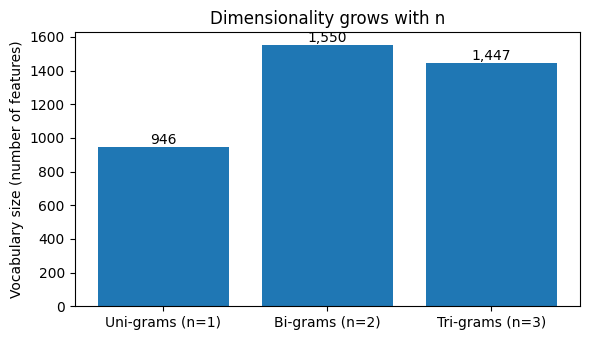

In [21]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(comparison.index, comparison["vocabulary size (columns)"])
ax.set_ylabel("Vocabulary size (number of features)")
ax.set_title("Dimensionality grows with n")
for i, v in enumerate(comparison["vocabulary size (columns)"]):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom")
plt.tight_layout(); plt.show()

**Observation (Problem 5): dimensionality of the vocabulary**

Things to look for in the table above:

- The vocabulary (number of columns) is **larger** for bi-grams than uni-grams, and larger again for tri-grams. A document of `k` words has about `k-1` bi-grams and `k-2` tri-grams, but almost every one of them is a **new, different** combination, so the unique n-gram count grows quickly.
- The matrix gets **much sparser**: almost every cell is zero.
- The share of items that occur **only once** climbs towards 100% for tri-grams. A feature seen once cannot help a model generalise.
- The most frequent bi-gram or tri-gram is repeated far fewer times than the most frequent single word.
- With only 168 short documents, this effect is extreme. A bigger corpus would see more repeats, but the **curse of dimensionality** still applies.
- Trade-off: n-grams give extra context (word order) at the cost of huge, sparse, memory-hungry feature matrices. Common fixes: set `min_df`, `max_features`, or use only up to bi-grams.

*Write your own conclusion using the actual numbers from your run:*

## Problem 6. TF-IDF

**Why:** Bag of Words treats every word as equally important. TF-IDF **down-weights words that appear in many documents** (they do not help tell documents apart) and **up-weights words that are rare and specific**.

- **TF** (term frequency): how often the word appears in this document
- **IDF** (inverse document frequency): how rare the word is across all documents

```
TF(t, d)  = count of t in d  (or count / words in d)
IDF(t)    = log( N / df(t) )          N = number of documents, df(t) = documents containing t
TFIDF     = TF x IDF
```
scikit-learn uses the **smoothed** version `IDF(t) = ln( (1 + N) / (1 + df(t)) ) + 1` and then L2-normalises each row.

**Pseudocode**
```
N = number of documents
FOR each word IN vocabulary:
    df[word]  = number of documents that contain word
    idf[word] = ln( (1 + N) / (1 + df[word]) ) + 1

FOR each document:
    FOR each word IN vocabulary:
        tfidf[document][word] = count(word, document) * idf[word]
    divide the row by its length (L2 norm)

SORT words by idf to see the most common (low idf) and most distinctive (high idf) words
```

In [22]:
# From scratch (idf scores)
N = len(df)
doc_freq = np.asarray((bow_manual > 0).sum(axis=0)).ravel()      # df(t): documents containing each word

idf_manual = np.log((1 + N) / (1 + doc_freq)) + 1                # smoothed idf (scikit-learn's formula)
idf_plain  = np.log(N / doc_freq)                                # textbook idf

tfidf_manual = bow_manual * idf_manual
tfidf_manual = tfidf_manual / np.linalg.norm(tfidf_manual, axis=1, keepdims=True)   # L2 normalise rows
print("TF-IDF matrix shape:", tfidf_manual.shape)

TF-IDF matrix shape: (168, 946)


In [23]:
# With scikit-learn
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(token_pattern=r"\S+", lowercase=False)
X_tfidf = tfidf.fit_transform(df["clean_text"])

print("TF-IDF matrix shape:", X_tfidf.shape)
print("Vocabulary size    :", len(tfidf.vocabulary_))
print("Same IDF as manual? ", np.allclose(tfidf.idf_, idf_manual))
print("Same TF-IDF matrix? ", np.allclose(X_tfidf.toarray(), tfidf_manual))

TF-IDF matrix shape: (168, 946)
Vocabulary size    : 946
Same IDF as manual?  True
Same TF-IDF matrix?  True


In [24]:
# Vocabulary and IDF score of every word
idf_df = pd.DataFrame({
    "word": tfidf.get_feature_names_out(),
    "idf (sklearn, smoothed)": tfidf.idf_,
    "idf (textbook ln(N/df))": idf_plain,
    "doc_freq": doc_freq,
}).sort_values("idf (sklearn, smoothed)").reset_index(drop=True)

print("Vocabulary (word -> column index), first 15:", dict(list(tfidf.vocabulary_.items())[:15]))
print()
print("LOWEST idf: appear in many documents, least informative")
display(idf_df.head(10))
print("HIGHEST idf: appear in a single document, most distinctive")
display(idf_df.tail(10))

Vocabulary (word -> column index), first 15: {'two': 889, 'petty': 630, 'criminal': 201, 'hire': 411, 'retired': 712, 'police': 640, 'officer': 600, 'capture': 123, 'ruthless': 742, 'dacoit': 207, 'terrorise': 848, 'village': 915, 'friendship': 354, 'revenge': 717, 'iconic': 431}

LOWEST idf: appear in many documents, least informative


,word,"idf (sklearn, smoothed)",idf (textbook ln(N/df)),doc_freq
0,love,2.466337,1.486378,38
1,man,2.546380,1.568616,35
2,woman,2.728701,1.756668,29
3,fall,3.038856,2.079442,21
4,family,3.134166,2.179525,19
5,young,3.185460,2.233592,18
6,life,3.296685,2.351375,16
7,two,3.357310,2.415914,15
8,become,3.490841,2.559015,13
9,take,3.490841,2.559015,13


HIGHEST idf: appear in a single document, most distinctive


,word,"idf (sklearn, smoothed)",idf (textbook ln(N/df)),doc_freq
936,affected,5.436752,5.123964,1
937,affair,5.436752,5.123964,1
938,advocate,5.436752,5.123964,1
939,advance,5.436752,5.123964,1
940,adult,5.436752,5.123964,1
941,adopt,5.436752,5.123964,1
942,admire,5.436752,5.123964,1
943,actor,5.436752,5.123964,1
944,zoya,5.436752,5.123964,1
945,13th,5.436752,5.123964,1


In [25]:
# Top TF-IDF words of one movie vs its raw counts
def top_tfidf_words(row_index, k=8):
    row = X_tfidf[row_index].toarray().ravel()
    order = row.argsort()[::-1][:k]
    names = tfidf.get_feature_names_out()
    return pd.DataFrame({"word": names[order], "tfidf": row[order].round(3),
                         "bow_count": X_bow[row_index].toarray().ravel()[order]})

i = 0
print("Movie:", df["movie"].iloc[i])
print(df["description"].iloc[i])
display(top_tfidf_words(i))

Movie: Sholay
Two petty criminals are hired by a retired police officer to capture a ruthless dacoit terrorising a village. Friendship, revenge and iconic dialogue define this curry-western classic.


,word,tfidf,bow_count
0,petty,0.25,1
1,iconic,0.25,1
2,curry,0.25,1
3,dacoit,0.25,1
4,western,0.25,1
5,retired,0.25,1
6,define,0.25,1
7,dialogue,0.25,1


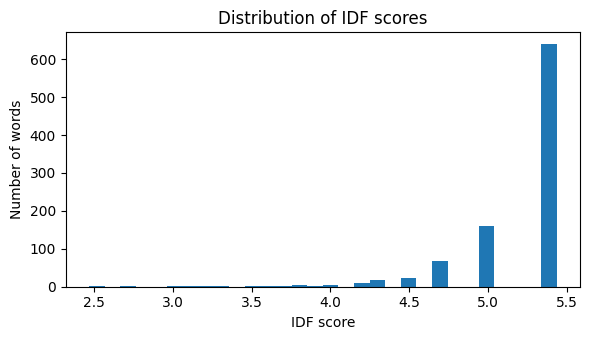

In [26]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(tfidf.idf_, bins=30)
ax.set_xlabel("IDF score"); ax.set_ylabel("Number of words")
ax.set_title("Distribution of IDF scores")
plt.tight_layout(); plt.show()

**Observation (Problem 6)**

- Which words have the **lowest** IDF? Why (they occur in many documents, so they do not help separate one movie from another)?
- Which have the **highest** IDF? How many documents do they appear in?
- Compare the top TF-IDF words of a movie with its raw counts. Do the TF-IDF words describe the movie better?
- Why is a word like `love`, which is the most frequent word, not the highest-scoring one?
- How do TF-IDF scores differ from BoW counts when used as features for a genre classifier?

*Your answer:*

## Summary of representations

| Representation | One row represents | Values | Captures word order | Captures word importance |
|---|---|---|---|---|
| One Hot Encoding | a single word | 0 / 1 | No | No |
| Bag of Words | a whole document | counts | No | No |
| Bag of n-grams | a whole document | counts of n-grams | Partly (local order) | No |
| TF-IDF | a whole document | weighted scores | No | Yes |

## Next steps
Use the BoW or TF-IDF matrix as input features to train a **genre classifier** (e.g. Logistic Regression or Naive Bayes), and try `min_df`, `max_features` and `ngram_range=(1, 2)` to control the dimensionality.